In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
import seaborn as sns
import uproot, os, logging, json, random, wandb
import awkward as ak
# import torch
from sklearn.metrics import roc_curve, roc_auc_score, auc, accuracy_score, log_loss
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from scipy.stats import randint, uniform
from matplotlib.ticker import FormatStrFormatter
from collections import Counter

# ML model
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import roc_auc_score, roc_curve, log_loss, accuracy_score
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Config
from bdt_config import sample_dict, zbi, getVarDict
from bdt_config import Vars, Vars2, Vars3, Vars_drop, Vars_plot
from bdt_config import variables, ntuple_name, ntuple_name_BDT

# Set up plot defaults
import matplotlib as mpl
mpl.rcParams['figure.figsize'] = 12.0,8.0  # Roughly 11 cm wde by 8 cm high
mpl.rcParams['font.size'] = 14.0 # Use 14 point font
sns.set(style="whitegrid")

# Check for gpu
# torch.cuda.is_available()

In [2]:
path = '/home/jlai/dark_photon/code/bdt_saving_all.csv'
df = pd.read_csv(path)
df.describe()

,event,VertexBDTScore,dmet,dphi_jj,dphi_met_phterm,dphi_met_jetterm,ph_phi,jet_central_eta,met,metsig,metsigres,n_jet_central,balance,ph_eta,ph_pt,weights,label
count,5.802448e+06,5.802448e+06,5.802448e+06,5.802448e+06,5.802448e+06,5.802448e+06,5.802448e+06,5.802448e+06,5.802448e+06,5.802448e+06,5.802448e+06,5.802448e+06,5.802448e+06,5.802448e+06,5.802448e+06,5.802448e+06,5.802448e+06
mean,3.036208e+08,2.117912e-01,-2.197616e+02,-3.763413e+02,6.494698e-01,-3.597573e+01,-1.375260e-02,-5.482588e+01,2.082885e+05,1.155469e+01,2.648137e+04,1.824498e+00,-5.227531e+01,9.156922e-01,5.562347e+05,5.103776e-02,1.357617e-02
std,7.530972e+08,5.852767e-02,8.406490e+03,4.849474e+02,7.742590e-01,1.861432e+02,1.825615e+00,2.275217e+02,1.514158e+05,8.900068e+00,2.193242e+04,8.765497e-01,2.281624e+02,6.403560e-01,7.663613e+05,5.065387e-01,1.157232e-01
min,3.000000e+00,1.000000e-01,-1.976306e+05,-9.990000e+02,0.000000e+00,-9.990000e+02,-3.141592e+00,-9.990000e+02,1.000000e+05,2.165612e-01,8.525812e+03,0.000000e+00,-9.990000e+02,1.202736e-06,5.000019e+04,-2.856596e+00,0.000000e+00
25%,1.442647e+07,1.665966e-01,0.000000e+00,-9.990000e+02,9.945029e-02,-1.342734e+00,-1.620170e+00,-9.027328e-01,1.199553e+05,4.443005e+00,1.251723e+04,1.000000e+00,1.083555e+00,3.816748e-01,9.637630e+04,1.878519e-04,0.000000e+00
50%,5.210206e+07,2.145679e-01,0.000000e+00,4.380492e-01,3.017852e-01,-5.919668e-02,-1.263396e-02,-6.856851e-02,1.575551e+05,1.027066e+01,1.815946e+04,2.000000e+00,1.406614e+00,7.915234e-01,1.943031e+05,2.890409e-03,0.000000e+00
75%,9.291294e+07,2.559026e-01,0.000000e+00,1.546274e+00,9.032724e-01,8.243264e-01,1.594042e+00,6.774481e-01,2.376736e+05,1.565584e+01,3.303395e+04,3.000000e+00,2.536895e+00,1.316551e+00,6.370927e+05,1.649684e-02,0.000000e+00
max,5.967937e+09,4.183918e-01,1.347015e+05,3.141591e+00,3.140348e+00,3.141593e+00,3.141590e+00,2.500000e+00,6.946651e+07,3.986008e+02,8.341812e+06,3.000000e+00,5.815950e+02,2.518129e+00,5.041646e+06,2.068407e+02,1.000000e+00


In [3]:
Vars2 = [
    "VertexBDTScore", "dmet", "dphi_jj", "dphi_met_phterm", 
    "dphi_met_jetterm", "met", "metsig", "balance", "ph_eta", 
    "ph_pt", "event",  "weights",  "label", "process",
    # "ph_phi", "metsigres", "jet_central_eta"
]
Vars3 = []
Vars_drop = ['event', 'weights', 'label', 'process', 'abs_weights']

In [4]:
# === Data Perparation ===
df_Vars2 = df[Vars2].copy()
df_Vars3 = df[Vars3].copy()

df_Vars3.replace(-999, np.nan, inplace=True)
df_Vars3_inverted = 1 / df_Vars3.replace({0: np.nan})  # Avoid division by zero

df_ml_input = pd.concat([df_Vars2, df_Vars3_inverted], axis=1)
df_ml_input.replace(-999, np.nan, inplace=True)
print("Number of event with negative weights :", np.sum(df_ml_input.weights < 0))
# df_ml_input["weights"] = df_ml_input["weights"].abs() # some of the weights are negative
df_ml_input["abs_weights"] = df_ml_input["weights"].abs()

display(df_ml_input.describe())

print("Number of nan in each variable: ")
print(df_ml_input.isna().sum())

# Define X (features) and y (labels)
# Vars_drop = ['weights', 'label', 'process']
X = df_ml_input.drop(Vars_drop, axis=1)
y = df_ml_input['label']
weights = df_ml_input['abs_weights']

random_num = random.randint(1, 100)
print("random number: ", random_num)

X_train, X_test, y_train, y_test, sw_train, sw_test = train_test_split(
    X, y, weights, test_size=0.3, random_state=random_num, stratify=y)

Number of event with negative weights : 293263


,VertexBDTScore,dmet,dphi_jj,dphi_met_phterm,dphi_met_jetterm,met,metsig,balance,ph_eta,ph_pt,event,weights,label,abs_weights
count,5.802448e+06,5.802448e+06,3.611677e+06,5.802448e+06,5.593489e+06,5.802448e+06,5.802448e+06,5.484006e+06,5.802448e+06,5.802448e+06,5.802448e+06,5.802448e+06,5.802448e+06,5.802448e+06
mean,2.117912e-01,-2.197616e+02,1.351070e+00,6.494698e-01,4.874342e-04,2.082885e+05,1.155469e+01,2.698537e+00,9.156922e-01,5.562347e+05,3.036208e+08,5.103776e-02,1.357617e-02,5.287981e-02
std,5.852767e-02,8.406490e+03,9.171524e-01,7.742590e-01,1.849243e+00,1.514158e+05,8.900068e+00,3.703316e+00,6.403560e-01,7.663613e+05,7.530972e+08,5.065387e-01,1.157232e-01,5.063498e-01
min,1.000000e-01,-1.976306e+05,4.768372e-07,0.000000e+00,-3.141592e+00,1.000000e+05,2.165612e-01,2.645603e-02,1.202736e-06,5.000019e+04,3.000000e+00,-2.856596e+00,0.000000e+00,0.000000e+00
25%,1.665966e-01,0.000000e+00,5.330704e-01,9.945029e-02,-9.172652e-01,1.199553e+05,4.443005e+00,1.119501e+00,3.816748e-01,9.637630e+04,1.442647e+07,1.878519e-04,0.000000e+00,4.353040e-04
50%,2.145679e-01,0.000000e+00,1.199213e+00,3.017852e-01,3.780246e-03,1.575551e+05,1.027066e+01,1.470994e+00,7.915234e-01,1.943031e+05,5.210206e+07,2.890409e-03,0.000000e+00,3.686935e-03
75%,2.559026e-01,0.000000e+00,2.130656e+00,9.032724e-01,9.260491e-01,2.376736e+05,1.565584e+01,2.662655e+00,1.316551e+00,6.370927e+05,9.291294e+07,1.649684e-02,0.000000e+00,1.837834e-02
max,4.183918e-01,1.347015e+05,3.141591e+00,3.140348e+00,3.141593e+00,6.946651e+07,3.986008e+02,5.815950e+02,2.518129e+00,5.041646e+06,5.967937e+09,2.068407e+02,1.000000e+00,2.068407e+02


Number of nan in each variable: 
VertexBDTScore            0
dmet                      0
dphi_jj             2190771
dphi_met_phterm           0
dphi_met_jetterm     208959
met                       0
metsig                    0
balance              318442
ph_eta                    0
ph_pt                     0
event                     0
weights                   0
label                     0
process                   0
abs_weights               0
dtype: int64
random number:  61


In [5]:
loaded_model = XGBClassifier()
loaded_model.load_model("/home/jlai/dark_photon/code/bdt_output_model.json")

In [6]:
df['MLBDTScore'] = loaded_model.predict_proba(df_ml_input.drop(Vars_drop, axis=1))[:, 1]
df

,event,VertexBDTScore,dmet,dphi_jj,dphi_met_phterm,dphi_met_jetterm,ph_phi,jet_central_eta,met,metsig,metsigres,n_jet_central,balance,ph_eta,ph_pt,process,weights,label,MLBDTScore
0,460670,0.230841,0.000,2.217201,2.453144,0.404135,-3.017065,0.406876,121740.016,6.135134,19843.090,2,0.903510,0.814938,169793.550,mc23d_ggHyyd_y,0.023093,1,0.012245
1,464023,0.268107,0.000,0.415064,1.710044,0.295024,-2.141560,-0.497805,219804.020,8.230965,26704.527,3,0.801790,1.534842,54682.950,mc23d_ggHyyd_y,0.022701,1,0.003486
2,460749,0.157550,0.000,2.241866,1.125051,0.373895,-1.635266,0.482204,105225.660,7.327814,14359.762,2,0.869816,1.825286,50311.215,mc23d_ggHyyd_y,0.022121,1,0.004724
3,464564,0.323496,0.000,1.608893,2.126570,-0.382360,-2.778662,1.126665,154065.080,8.421028,18295.281,3,0.831923,1.597995,106113.170,mc23d_ggHyyd_y,0.022558,1,0.012340
4,464588,0.303827,0.000,-999.000000,2.271234,0.218884,1.453807,-1.147197,186557.550,10.410183,17920.680,1,1.034199,0.693471,64250.664,mc23d_ggHyyd_y,0.022558,1,0.025775
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5802443,331777,0.195819,0.000,1.231700,1.493632,0.555683,-2.334605,-0.252590,100596.836,8.070360,12464.975,2,1.302860,0.980078,63760.707,mc23e_ZHyyd_y,0.002753,1,0.035546
5802444,331809,0.231813,0.000,1.486782,1.590998,-0.558745,0.737153,0.253948,118073.410,9.868857,11964.243,2,1.146292,0.224520,73072.760,mc23e_ZHyyd_y,0.002736,1,0.039098
5802445,333757,0.234257,8589.406,-999.000000,1.968750,-0.411448,0.962833,-2.188100,117367.340,5.046452,23257.398,1,1.526038,1.136811,65453.566,mc23e_ZHyyd_y,0.000858,1,0.004358
5802446,331846,0.257630,11346.906,0.938734,1.746998,-0.458405,-0.117869,-1.380291,137840.100,8.032137,17161.074,3,1.088692,0.044623,66393.390,mc23e_ZHyyd_y,0.003216,1,0.037149


In [7]:
df.to_csv("/home/jlai/dark_photon/code/bdt_output_all.csv", index=False)

In [8]:
ntuple_names = np.unique(df['process'])
for i in range(len(ntuple_names)):
    process = ntuple_names[i]
    df_tmp = df[df.process == process]
    df_tmp = df_tmp.replace(np.nan, -999)
    df_tmp = df_tmp[df_tmp.MLBDTScore > 0.02]
    print(process, sum(df_tmp['weights']))

data23_eprobe 302.04324692999967
data23_y 144.321
data24_eprobe 1435.6475493999992
data24_y 474.313
mc23d_VBFHyyd_y 8.47835780042715
mc23d_WHyyd_y 2.292533819667203
mc23d_Wgamma_y 218.39497484022058
mc23d_ZHyyd_y 1.1846166820393829
mc23d_Zgamma_y 110.70388570393379
mc23d_gammajet_direct_y 32.058932609972075
mc23d_ggHyyd_y 39.14638403838
mc23e_VBFHyyd_y 34.60764173585061
mc23e_WHyyd_y 9.376498002454007
mc23e_Wgamma_y 887.7601614600673
mc23e_ZHyyd_y 4.8859609733202705
mc23e_Zgamma_y 468.4091352333924
mc23e_gammajet_direct_y 92.50281851500466
mc23e_ggHyyd_y 157.92183853957212


In [ ]:
# 5. Load your trained model
# (If your model is already in memory, you can skip this block and just use your model variable)


# 6. Evaluate the model to get the BDT scores
# predict_proba outputs an array of shape (n_samples, 2): [prob_background, prob_signal]
# We slice [:, 1] to get the probability of it being the signal class
bdt_scores = loaded_model.predict_proba(X_new)[:, 1]

# 7. Append the new BDT scores to your original DataFrame
df_new['MLBDTScore'] = bdt_scores

# 8. Save the updated DataFrame to a new CSV file
output_path = 'new_signal_evaluated.csv'
df_new.to_csv(output_path, index=False)

print(f"Successfully evaluated {len(df_new)} events.")
print(f"Saved results with MLBDTScore to: {output_path}")

In [32]:

# === Model with best parameters ===
model = XGBClassifier(
    tree_method='hist',
    device='cuda',
    max_depth=10,
    learning_rate=0.08567,
    n_estimators=387,
    subsample=0.2547,
    gamma=0.511,
    early_stopping_rounds=10,
    eval_metric=['logloss', 'error', 'auc'],
    use_label_encoder=False,
    missing=np.nan
)

model.fit(
    X_train, y_train,
    sample_weight=sw_train,
    eval_set=[(X_test, y_test)],
    sample_weight_eval_set=[sw_test],
    verbose=True
)

# === Evaluation ===
y_test_pred_proba = model.predict_proba(X_test)[:, 1]
Auc = roc_auc_score(y_test, y_test_pred_proba, sample_weight=sw_test)
df_output = df_ml_input.copy()
df_output["MLBDTScore"] = model.predict_proba(df_ml_input.drop(Vars_drop, axis=1))[:, 1]
df["MLBDTScore"] = model.predict_proba(df_ml_input.drop(Vars_drop, axis=1))[:, 1]
print(f"Test ROC AUC: {Auc:.4f}")

# save the dataframe to csv file
# df.to_csv("/data/jlai/ntups/bdt_output/bdt_0mu.csv", index=False)

# save the model
# model.save_model("/data/jlai/ntups/bdt_output/bdt_0mu_model.json")

[0]	validation_0-logloss:0.11641	validation_0-error:0.00023	validation_0-auc:0.82375
[1]	validation_0-logloss:0.10636	validation_0-error:0.00023	validation_0-auc:0.82442
[2]	validation_0-logloss:0.09724	validation_0-error:0.00023	validation_0-auc:0.82460
[3]	validation_0-logloss:0.08894	validation_0-error:0.00023	validation_0-auc:0.84203
[4]	validation_0-logloss:0.08139	validation_0-error:0.00023	validation_0-auc:0.84203
[5]	validation_0-logloss:0.07452	validation_0-error:0.00023	validation_0-auc:0.84206
[6]	validation_0-logloss:0.06826	validation_0-error:0.00023	validation_0-auc:0.84204
[7]	validation_0-logloss:0.06255	validation_0-error:0.00023	validation_0-auc:0.84205
[8]	validation_0-logloss:0.05734	validation_0-error:0.00023	validation_0-auc:0.84205


[17:49:41] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.



[9]	validation_0-logloss:0.05258	validation_0-error:0.00023	validation_0-auc:0.84211
[10]	validation_0-logloss:0.04824	validation_0-error:0.00023	validation_0-auc:0.84203
[11]	validation_0-logloss:0.04428	validation_0-error:0.00023	validation_0-auc:0.84197
[12]	validation_0-logloss:0.04065	validation_0-error:0.00023	validation_0-auc:0.84221
[13]	validation_0-logloss:0.03734	validation_0-error:0.00023	validation_0-auc:0.84220
[14]	validation_0-logloss:0.03431	validation_0-error:0.00023	validation_0-auc:0.84219
[15]	validation_0-logloss:0.03154	validation_0-error:0.00023	validation_0-auc:0.84227
[16]	validation_0-logloss:0.02900	validation_0-error:0.00023	validation_0-auc:0.84228
[17]	validation_0-logloss:0.02668	validation_0-error:0.00023	validation_0-auc:0.84227
[18]	validation_0-logloss:0.02456	validation_0-error:0.00023	validation_0-auc:0.84236
[19]	validation_0-logloss:0.02261	validation_0-error:0.00023	validation_0-auc:0.84233
[20]	validation_0-logloss:0.02083	validation_0-error:0.

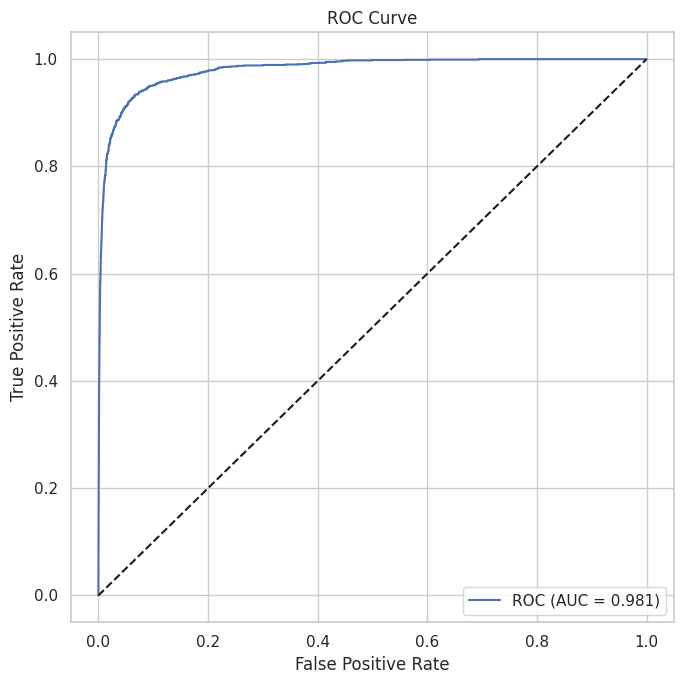

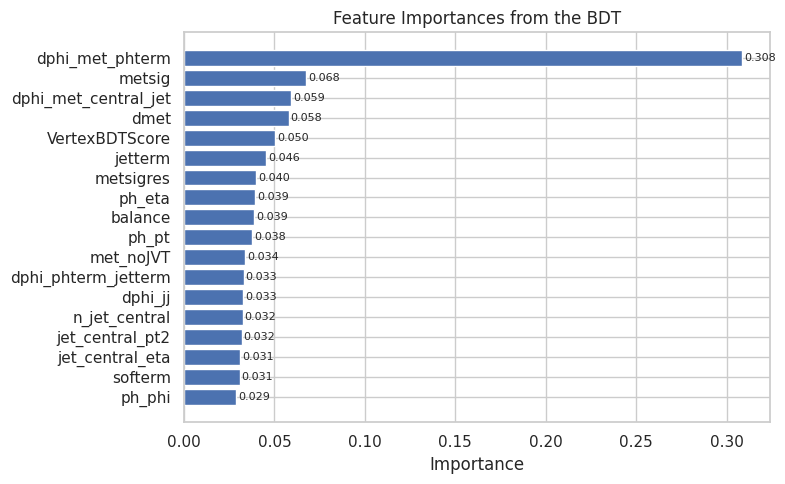

In [33]:
fpr, tpr, _ = roc_curve(y_test, y_test_pred_proba, sample_weight=sw_test)
plt.figure(figsize=(7, 7))
plt.plot(fpr, tpr, label="ROC (AUC = {:.3f})".format(roc_auc_score(y_test, y_test_pred_proba, sample_weight=sw_test)))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()

# plt.savefig("roc_randomsearch.png")
plt.show()

importances = model.feature_importances_
indices = np.argsort(importances)
selected_columns = df_ml_input.drop(Vars_drop, axis=1).columns

plt.figure(figsize=(8, 5))
bars = plt.barh(range(len(selected_columns)), importances[indices], align='center')

# Set y-ticks with feature names
plt.yticks(range(len(selected_columns)), [selected_columns[i] for i in indices])
plt.xlabel('Importance')
plt.title('Feature Importances from the BDT')

# Annotate each bar with the importance value
for i, bar in enumerate(bars):
    width = bar.get_width()
    plt.text(width + 0.001, bar.get_y() + bar.get_height()/2,
             f'{width:.3f}', va='center', fontsize=8)
plt.tight_layout()
# plt.savefig("feature_importance.png")
plt.show()

In [36]:
def compute_significance(df, cut=0.5):
    s = df[(df["label"] == 1) & (df["MLBDTScore"] >= cut)]["weights"].sum()
    b = df[(df["label"] == 0) & (df["MLBDTScore"] >= cut)]["weights"].sum()
    return s / np.sqrt(b) if b > 0 else 0, s/df[(df['label'] == 1)]['weights'].sum()

max_sig, acceptance = max(compute_significance(df_output, cut) for cut in np.arange(0.0, 0.15, 0.01))
print(f"Max S/√B: {max_sig:.3f}, Acceptance: {acceptance*100} %")

Max S/√B: 4.003, Acceptance: 38.11868675216264 %


In [13]:
ntuple_names = np.unique(df_output['process'])
for i in range(len(ntuple_names)):
    process = ntuple_names[i]
    df_tmp = df_output[df_output.process == process]
    df_tmp = df_tmp.replace(np.nan, -999)
    df_tmp = df_tmp[df_tmp.MLBDTScore > 0.04]
    print(process, sum(df_tmp['weights']))

Wgamma 789.6597103356083
Wjets 675.8530084242116
Zgamma 420.4914626049809
Zjets 1.4754961619473759
data23 41.703696516930236
gammajet_direct 5.8786821963088585
ggHyyd 176.07867482430558


Saved plot to significance_MLBDTScore_lowercut.png


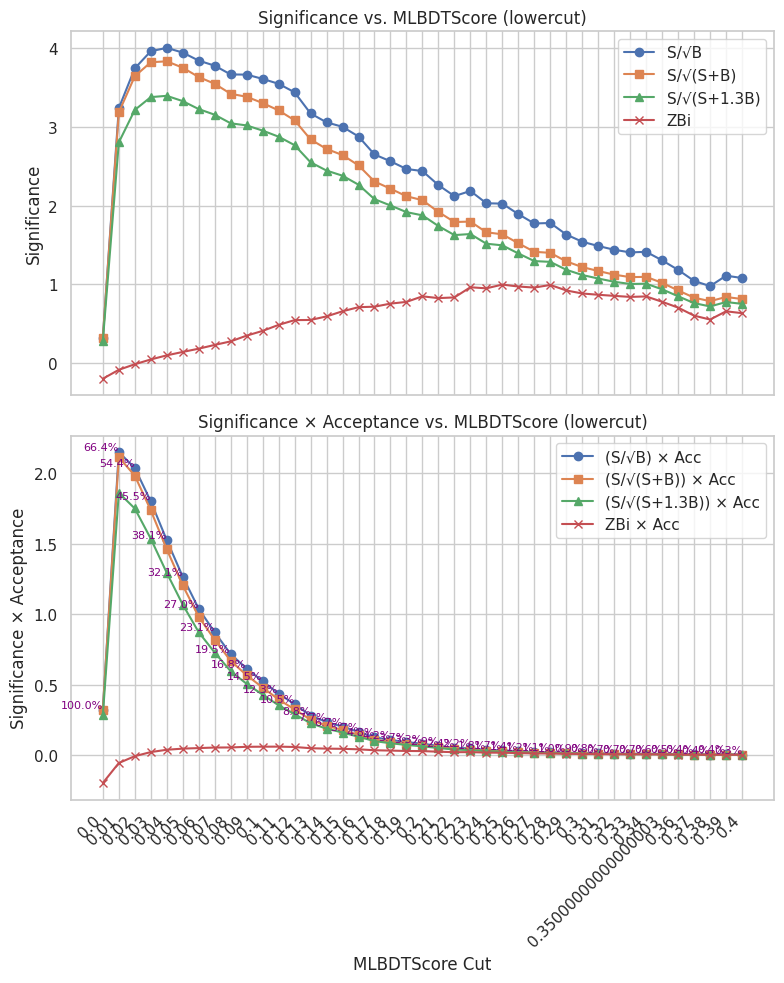

In [38]:
def binomial_significance(s, b):
    return s / np.sqrt(b) if b > 0 else 0

def s_over_sb(s, b):
    return s / np.sqrt(s + b) if (s + b) > 0 else 0

def s_over_s1p3b(s, b):
    return s / np.sqrt(s + 1.3 * b) if (s + 1.3 * b) > 0 else 0

def scan_significance(df, cut_var="MLBDTScore", cut_type="lowercut", cuts=np.arange(0, 0.71, 0.01)):
    sig_sqrtb = []
    sig_sqrt_sb = []
    sig_sqrt_s1p3b = []
    sig_zbi = []

    sigacc_sqrtb = []
    sigacc_sqrt_sb = []
    sigacc_sqrt_s1p3b = []
    sigacc_zbi = []

    acc_values = []

    df_sig = df[df["label"] == 1]
    df_bkg = df[df["label"] == 0]
    total_sig_weight = df_sig["weights"].sum()

    for cut in cuts:
        if cut_type == "lowercut":
            sig_cut = df_sig[df_sig[cut_var] >= cut]
            bkg_cut = df_bkg[df_bkg[cut_var] >= cut]
        elif cut_type == "uppercut":
            sig_cut = df_sig[df_sig[cut_var] <= cut]
            bkg_cut = df_bkg[df_bkg[cut_var] <= cut]
        else:
            raise ValueError("Invalid cut type")

        s = sig_cut["weights"].sum()
        b = bkg_cut["weights"].sum()
        acceptance = s / total_sig_weight if total_sig_weight > 0 else 0

        # Compute significance
        sig1 = binomial_significance(s, b)
        sig2 = s_over_sb(s, b)
        sig3 = s_over_s1p3b(s, b)
        sig4 = zbi(s, b)

        sig_sqrtb.append(sig1)
        sig_sqrt_sb.append(sig2)
        sig_sqrt_s1p3b.append(sig3)
        sig_zbi.append(sig4)

        sigacc_sqrtb.append(sig1 * acceptance)
        sigacc_sqrt_sb.append(sig2 * acceptance)
        sigacc_sqrt_s1p3b.append(sig3 * acceptance)
        sigacc_zbi.append(sig4 * acceptance)

        acc_values.append(acceptance * 100)

    return cuts, acc_values, sig_sqrtb, sig_sqrt_sb, sig_sqrt_s1p3b, sig_zbi, \
           sigacc_sqrtb, sigacc_sqrt_sb, sigacc_sqrt_s1p3b, sigacc_zbi


def plot_significance(cuts, acc, sig1, sig2, sig3, sig4,
                      sigacc1, sigacc2, sigacc3, sigacc4,
                      cut_var, cut_type, save_path):

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 10), sharex=True)

    # Plot Significance
    ax1.plot(cuts, sig1, marker='o', label='S/√B')
    ax1.plot(cuts, sig2, marker='s', label='S/√(S+B)')
    ax1.plot(cuts, sig3, marker='^', label='S/√(S+1.3B)')
    ax1.plot(cuts, sig4, marker='x', label='ZBi')

    ax1.set_ylabel('Significance')
    ax1.set_title(f'Significance vs. {cut_var} ({cut_type})')
    ax1.grid(True)
    ax1.legend()

    # Plot Significance × Acceptance
    ax2.plot(cuts, sigacc1, marker='o', label='(S/√B) × Acc')
    ax2.plot(cuts, sigacc2, marker='s', label='(S/√(S+B)) × Acc')
    ax2.plot(cuts, sigacc3, marker='^', label='(S/√(S+1.3B)) × Acc')
    ax2.plot(cuts, sigacc4, marker='x', label='ZBi × Acc')

    for i, txt in enumerate(acc):
        ax2.text(cuts[i], sigacc1[i], f'{txt:.1f}%', fontsize=8, color='purple', ha='right', va='bottom')

    ax2.set_xlabel(f'{cut_var} Cut')
    ax2.set_ylabel('Significance × Acceptance')
    ax2.set_title(f'Significance × Acceptance vs. {cut_var} ({cut_type})')
    ax2.grid(True)
    ax2.legend()
    ax2.xaxis.set_major_formatter(FormatStrFormatter('%.2f'))
    ax2.set_xticks(cuts)
    ax2.set_xticklabels(cuts, rotation=45, ha='right')

    plt.tight_layout()
    plt.savefig(save_path)
    print(f"Saved plot to {save_path}")
    plt.show()


cut_var = "MLBDTScore"
cut_type = "lowercut"
cut_values = np.arange(0, 0.4 + 3e-12, 0.01)

(cuts, acc, sig1, sig2, sig3, sig4,
 sigacc1, sigacc2, sigacc3, sigacc4) = scan_significance(df_output, cut_var, cut_type, cut_values)

plot_significance(
    cuts, acc, sig1, sig2, sig3, sig4,
    sigacc1, sigacc2, sigacc3, sigacc4,
    cut_var=cut_var,
    cut_type=cut_type,
    save_path=f"significance_{cut_var}_{cut_type}.png"
)


In [45]:
import numpy as np

def debug_one_var(
    var_name,
    signal_name='ggHyyd',
    pre_cut_var='MLBDTScore',
    pre_cut_thr=0.04,
    sigma_b_frac=0.3
):
    print("="*80)
    print(f"[DEBUG] Variable: {var_name} | Preselection: {pre_cut_var} >= {pre_cut_thr}")
    print("="*80)

    # Collect arrays per process
    bg_values, bg_weights, bg_labels = [], [], []
    sig_values, sig_weights = [], []
    all_proc_stats = []

    for process in ntuple_names:
        df_tmp = df[df.process == process]
        if pre_cut_var in df_tmp.columns:
            df_tmp = df_tmp[df_tmp[pre_cut_var] >= pre_cut_thr]

        if var_name not in df_tmp.columns:
            print(f"  [WARN] {var_name} not in dataframe for process {process}; skipping.")
            continue

        x = df_tmp[var_name].to_numpy()
        w = df_tmp['weights'].to_numpy()

        # Finite mask
        finite_mask = np.isfinite(x) & np.isfinite(w)
        n_nonfinite = x.size - finite_mask.sum()

        x = x[finite_mask].astype(np.float64, copy=False)
        w = w[finite_mask].astype(np.float64, copy=False)

        n_neg_w = (w < 0).sum()
        sum_w = w.sum()
        sum_w2 = (w**2).sum()
        x_min = np.nanmin(x) if x.size else np.nan
        x_max = np.nanmax(x) if x.size else np.nan

        all_proc_stats.append({
            "process": process,
            "n_events": x.size,
            "sum_w": float(sum_w),
            "sum_w2": float(sum_w2),
            "n_neg_w": int(n_neg_w),
            "n_nonfinite_dropped": int(n_nonfinite),
            "x_min": float(x_min) if np.isfinite(x_min) else x_min,
            "x_max": float(x_max) if np.isfinite(x_max) else x_max,
        })

        if process == signal_name:
            sig_values.append(x)
            sig_weights.append(w)
        else:
            bg_values.append(x)
            bg_weights.append(w)
            bg_labels.append(sample_dict.get(process, {}).get('legend', process))

    # Print per-process summary
    print("\n[Per-process stats after preselection & finite filtering]")
    for s in all_proc_stats:
        print(f"  {s['process']:>15} | n={s['n_events']:>7} | sum_w={s['sum_w']:>12.6g} "
              f"| sum_w2={s['sum_w2']:>12.6g} | neg_w={s['n_neg_w']:>6} "
              f"| nonfinite_dropped={s['n_nonfinite_dropped']:>4} "
              f"| x∈[{s['x_min']}, {s['x_max']}]")

    # Flatten
    sig_all = np.concatenate(sig_values) if sig_values else np.array([], dtype=np.float64)
    sig_wts = np.concatenate(sig_weights) if sig_weights else np.array([], dtype=np.float64)
    bg_all  = np.concatenate(bg_values)  if bg_values  else np.array([], dtype=np.float64)
    bg_wts  = np.concatenate(bg_weights) if bg_weights else np.array([], dtype=np.float64)

    print("\n[Merged stats]")
    print(f"  Signal: n={sig_all.size}, sum_w={sig_wts.sum():.6g}, neg_w={(sig_wts<0).sum()}")
    print(f"  Bkg   : n={bg_all.size}, sum_w={bg_wts.sum():.6g}, neg_w={(bg_wts<0).sum()}")

    # Load binning from your var config
    var_cfg = getVarDict(signal_name, signal_name, var_name=var_name)
    if var_name not in var_cfg:
        print(f"[ERROR] getVarDict did not return config for {var_name}. Got keys: {list(var_cfg.keys())}")
        return

    bins_cfg = var_cfg[var_name]['bins']
    # Robust bins: allow int or edges
    if np.isscalar(bins_cfg):
        if sig_all.size + bg_all.size:
            lo = np.nanmin(np.concatenate([sig_all, bg_all])) if (sig_all.size and bg_all.size) else (
                 np.nanmin(sig_all) if sig_all.size else np.nanmin(bg_all))
            hi = np.nanmax(np.concatenate([sig_all, bg_all])) if (sig_all.size and bg_all.size) else (
                 np.nanmax(sig_all) if sig_all.size else np.nanmax(bg_all))
            if not np.isfinite(lo) or not np.isfinite(hi) or lo == hi:
                lo, hi = 0.0, 1.0
        else:
            lo, hi = 0.0, 1.0
        bins = np.linspace(lo, hi, int(bins_cfg)+1)
    else:
        bins = np.asarray(bins_cfg, dtype=float)

    print("\n[Bin edges]")
    print(f"  nbins={len(bins)-1}, edges[0]={bins[0]}, edges[-1]={bins[-1]}")

    # Histograms
    S_counts, _ = np.histogram(sig_all, bins=bins, weights=sig_wts)
    B_counts, _ = np.histogram(bg_all,  bins=bins, weights=bg_wts)

    # Quick peek at first few bins
    show = min(10, len(S_counts))
    print("\n[First few bin contents]")
    for i in range(show):
        print(f"  bin {i:>3}: S={S_counts[i]:>12.6g} | B={B_counts[i]:>12.6g}")

    # Problematic bins
    idx_B_le0 = np.where(B_counts <= 0)[0]
    idx_SB_le0 = np.where(S_counts + B_counts <= 0)[0]
    idx_S1p3B_le0 = np.where(S_counts + 1.3*B_counts <= 0)[0]

    print("\n[Problematic bin indices]")
    print(f"  B<=0 bins          : {idx_B_le0.tolist()}")
    print(f"  S+B<=0 bins        : {idx_SB_le0.tolist()}")
    print(f"  S+1.3B<=0 bins     : {idx_S1p3B_le0.tolist()}")

    # Significance (safe)
    S_pos = np.clip(S_counts, 0.0, None)
    B_pos = np.clip(B_counts, 0.0, None)

    with np.errstate(divide='ignore', invalid='ignore'):
        sig_simple = np.where(B_pos > 0, S_pos/np.sqrt(B_pos), 0.0)
        sig_spb    = np.where(S_pos + B_pos > 0, S_pos/np.sqrt(S_pos + B_pos), 0.0)
        sig_s1p3b  = np.where(S_pos + 1.3*B_pos > 0, S_pos/np.sqrt(S_pos + 1.3*B_pos), 0.0)

    print("\n[Per-bin significance (first few)]")
    for i in range(show):
        print(f"  bin {i:>3}: S/√B={sig_simple[i]:>10.6g} | S/√(S+B)={sig_spb[i]:>10.6g} | S/√(S+1.3B)={sig_s1p3b[i]:>10.6g}")

    # Totals
    totS = float(np.nansum(S_pos))
    totB = float(np.nansum(B_pos))

    def safe_zbi(S, B, frac):
        try:
            return float(zbi(S, B, sigma_b_frac=frac))
        except Exception as e:
            print(f"  [WARN] zbi failed with S={S}, B={B}: {e}")
            return float("nan")

    tot_sig_sqrtB     = (totS/np.sqrt(totB))                  if totB > 0 else 0.0
    tot_sig_sqrtSB    = (totS/np.sqrt(totS + totB))           if (totS + totB) > 0 else 0.0
    tot_sig_sqrtS1p3B = (totS/np.sqrt(totS + 1.3*totB))       if (totS + 1.3*totB) > 0 else 0.0
    tot_zbi           = safe_zbi(totS, max(totB, 0.0), sigma_b_frac)

    print("\n[Totals]")
    print(f"  totS={totS:.6g}, totB={totB:.6g}")
    print(f"  S/√B={tot_sig_sqrtB:.6g} | S/√(S+B)={tot_sig_sqrtSB:.6g} | S/√(S+1.3B)={tot_sig_sqrtS1p3B:.6g} | ZBi={tot_zbi:.6g}")

    # ROC (only if both sides exist)
    if sig_all.size > 0 and bg_all.size > 0:
        y_true = np.concatenate([np.ones(sig_all.size, dtype=int), np.zeros(bg_all.size, dtype=int)])
        y_scores = np.concatenate([sig_all, bg_all])
        y_wts = np.concatenate([sig_wts, bg_wts])

        # Filter non-finite
        m = np.isfinite(y_scores) & np.isfinite(y_wts)
        y_true = y_true[m]; y_scores = y_scores[m]; y_wts = y_wts[m]

        try:
            from sklearn.metrics import roc_curve, auc
            fpr, tpr, _ = roc_curve(y_true, y_scores, sample_weight=y_wts)
            roc_auc = auc(fpr, tpr)
            print("\n[ROC]")
            print(f"  n_points={fpr.size}, AUC={roc_auc:.6g}, "
                  f"scores∈[{np.nanmin(y_scores):.6g}, {np.nanmax(y_scores):.6g}]")
        except Exception as e:
            print(f"  [WARN] ROC failed: {e}")
    else:
        print("\n[ROC] Skipped (empty signal or background after preselection).")

    # Log-scale feasibility (stacked background must be >0 per bin)
    can_log = (B_counts.size > 0) and np.all(np.isfinite(B_counts)) and np.all(B_counts > 0)
    print(f"\n[Log-scale OK?] {can_log} (requires all stacked B > 0)")
    print("="*80)

# ---- HOW TO RUN (example) ----
# debug_one_var("balance")     # replace with the variable that triggered warnings
debug_one_var("mt")

[DEBUG] Variable: mt | Preselection: MLBDTScore >= 0.04

[Per-process stats after preselection & finite filtering]
           Wgamma | n=   4321 | sum_w=     609.352 | sum_w2=     349.178 | neg_w=   391 | nonfinite_dropped=   0 | x∈[100.07932, 536.988]
            Wjets | n=   1462 | sum_w=     468.683 | sum_w2=     710.092 | neg_w=   177 | nonfinite_dropped=   0 | x∈[100.001015, 342.97833]
           Zgamma | n=   6614 | sum_w=     326.863 | sum_w2=     68.0212 | neg_w=   435 | nonfinite_dropped=   0 | x∈[100.01464, 629.2625]
            Zjets | n=     15 | sum_w=      1.4755 | sum_w2=    0.384216 | neg_w=     0 | nonfinite_dropped=   0 | x∈[100.43417, 136.46017]
           data23 | n=      4 | sum_w=     41.7037 | sum_w2=      437.27 | neg_w=     0 | nonfinite_dropped=   0 | x∈[100.79901, 131.10966]
  gammajet_direct | n=    164 | sum_w=     5.87868 | sum_w2=     15.9993 | neg_w=     0 | nonfinite_dropped=   0 | x∈[100.84532, 940.4442]
           ggHyyd | n=   1684 | sum_w=     176.0

In [47]:
from sklearn.metrics import roc_curve, roc_auc_score, auc, accuracy_score, log_loss

signal_name = 'ggHyyd'  # Define signal dataset
cut_name = 'bdt0mu'
corr_features = df.drop(Vars_drop, axis=1)

for cut_var_tmp in corr_features.columns:
# for cut_var_tmp in ['mt']:
    var_config = getVarDict(signal_name, 'ggHyyd', var_name=cut_var_tmp)
    
    for var in var_config:
        # print(var)
        bg_values = []     
        bg_weights = []    
        bg_colors = []     
        bg_labels = []     
    
        signal_values = [] 
        signal_weights = []
        signal_color = None 
        signal_label = None
    
        for j in range(len(ntuple_names)):
            process = ntuple_names[j]
            df_tmp = df[df.process == process]
            df_tmp = df_tmp[df_tmp.MLBDTScore >= 0.04]
            
            x = df_tmp[var]
            bins = var_config[var]['bins'] 
            # weights = df_tmp['weights']
            weights = abs(df_tmp['weights'])
            
            sample_info = sample_dict[process]
            color = sample_info['color']
            legend = sample_info['legend']
    
            
            if process == signal_name:  # signal
                signal_values.append(x)
                signal_weights.append(weights)
                signal_color = color
                signal_label = legend
            else:   # background
                bg_values.append(x)
                bg_weights.append(weights)
                bg_colors.append(color)
                bg_labels.append(legend)
    
        fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(12, 13), gridspec_kw={'height_ratios': [9, 4]})
    
        ax_top.hist(bg_values, bins=bins, weights=bg_weights, color=bg_colors,
                    label=bg_labels, stacked=True)
    
        ax_top.hist(signal_values, bins=bins, weights=signal_weights, color=signal_color,
                    label=signal_label, histtype='step', linewidth=2)
    
        signal_all = np.concatenate(signal_values) if len(signal_values) > 0 else np.array([])
        signal_weights_all = np.concatenate(signal_weights) if len(signal_weights) > 0 else np.array([])
    
        # Add error bar for signal (top plot)
        if len(signal_all) > 0:
            signal_counts, bin_edges = np.histogram(signal_all, bins=bins, weights=signal_weights_all)
            sum_weights_sq, _ = np.histogram(signal_all, bins=bins, weights=signal_weights_all**2)
            bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
            signal_errors = np.sqrt(sum_weights_sq)  # Poisson error sqrt(N)
    
            ax_top.errorbar(bin_centers, signal_counts, yerr=signal_errors, fmt='.', linewidth=2,
                            color=signal_color, capsize=0)
    
        ax_top.set_yscale('log')
        ax_top.set_ylim(0.0001, 1e11)
        ax_top.set_xlim(bins[0], bins[-1])
        ax_top.minorticks_on()
        ax_top.grid(True, which="both", linestyle="--", linewidth=0.5)
        ax_top.set_ylabel("Events")
        ax_top.legend(ncol=2)
        # ax_top.set_title("vtx_sumPt distribution")
    
        bg_all = np.concatenate(bg_values) if len(bg_values) > 0 else np.array([])
        bg_weights_all = np.concatenate(bg_weights) if len(bg_weights) > 0 else np.array([])
    
        # Compute the weighted histogram counts using np.histogram
        S_counts, _ = np.histogram(signal_all, bins=bins, weights=signal_weights_all)
        B_counts, _ = np.histogram(bg_all, bins=bins, weights=bg_weights_all)     
    
        # Compute per-bin significance
        sig_simple = np.zeros_like(S_counts, dtype=float)
        sig_s_plus_b = np.zeros_like(S_counts, dtype=float)
        sig_s_plus_1p3b = np.zeros_like(S_counts, dtype=float)
    
        sqrt_B = np.sqrt(B_counts)
        sqrt_SplusB = np.sqrt(S_counts + B_counts)
        sqrt_Splus1p3B = np.sqrt(S_counts + 1.3 * B_counts)
    
        # Avoid division by zero safely
        sig_simple = np.where(B_counts > 0, S_counts / sqrt_B, 0)
        sig_s_plus_b = np.where((S_counts + B_counts) > 0, S_counts / sqrt_SplusB, 0)
        sig_s_plus_1p3b = np.where((S_counts + 1.3 * B_counts) > 0, S_counts / sqrt_Splus1p3B, 0)
    
        # Add Binomial ExpZ per bin
        zbi_per_bin = np.array([
            zbi(S_counts[i], B_counts[i], sigma_b_frac=0.3)
            for i in range(len(S_counts))
        ])
    
        # Compute the bin centers for plotting
        bin_centers = 0.5 * (bins[:-1] + bins[1:])
    
        # Compute the total significance: total S / sqrt(total B)
        total_signal = np.sum(S_counts)
        total_bkg = np.sum(B_counts)
    
        if total_bkg > 0:
            total_sig_simple = total_signal / np.sqrt(total_bkg)
            total_sig_s_plus_b = total_signal / np.sqrt(total_signal + total_bkg)
            total_sig_s_plus_1p3b = total_signal / np.sqrt(total_signal + 1.3 * total_bkg)
            total_sig_binomial = zbi(total_signal, total_bkg, sigma_b_frac=0.3)
        else:
            total_sig_simple = total_sig_s_plus_b = total_sig_s_plus_1p3b = total_sig_binomial = 0
    
        # --- Plot all significance curves ---
        ax_bot.step(bin_centers, sig_simple, where='mid', color='chocolate', linewidth=2,
                    label=f"S/√B = {total_sig_simple:.4f}")
        ax_bot.step(bin_centers, sig_s_plus_b, where='mid', color='tomato', linewidth=2,
                    label=f"S/√(S+B) = {total_sig_s_plus_b:.4f}")
        ax_bot.step(bin_centers, sig_s_plus_1p3b, where='mid', color='orange', linewidth=2,
                    label=f"S/√(S+1.3B) = {total_sig_s_plus_1p3b:.4f}")
        ax_bot.step(bin_centers, zbi_per_bin, where='mid', color='plum', linewidth=2,
                    label=f"Binomial ExpZ = {total_sig_binomial:.4f}")
    
        ax_bot.set_xlabel(var_config[var]['title'])
        # ax_bot.set_xticks(np.linspace(bins[0], bins[-1], 11))
        ax_bot.set_ylabel("Significance")
        ax_bot.set_ylim(-0.8, 2)
        ax_top.set_xlim(bins[0], bins[-1])
    
        # Do not set a title on the bottom plot.
        ax_bot.set_title("")
    
        # Draw a legend with purple text.
        leg = ax_bot.legend()
        for text in leg.get_texts():
            text.set_color('purple')
    
        plt.xlim(bins[0], bins[-1])
        plt.tight_layout()
        plt.savefig(f"/data/jlai/dark_photon/jets_faking_photons/lumi135/mc23d_{cut_name}cut/{var}_nodijet.png")
        print(f"successfully saved to /data/jlai/dark_photon/jets_faking_photons/lumi135/mc23d_{cut_name}cut/{var}_nodijet.png")
        plt.close()
        # plt.show()
    
        y_true = np.concatenate([np.ones_like(signal_all), np.zeros_like(bg_all)])
        # Use the vtx_sumPt values as the classifier output.
        y_scores = np.concatenate([signal_all, bg_all])
        # Combine the weights for all events.
        y_weights = np.concatenate([signal_weights_all, bg_weights_all])
    
        # Compute the weighted ROC curve.
        fpr, tpr, thresholds = roc_curve(y_true, y_scores, sample_weight=y_weights)
        sorted_indices = np.argsort(fpr)
        fpr_sorted = fpr[sorted_indices]
        tpr_sorted = tpr[sorted_indices]
    
        roc_auc = auc(fpr_sorted, tpr_sorted)
    
        # Create a new figure for the ROC curve.
        plt.figure(figsize=(8, 8))
        plt.plot(fpr, tpr, lw=2, color='red', label=f'ROC curve (AUC = {roc_auc:.5f})')
        plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random chance')
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title(f"ROC Curve for {var}")
        plt.legend(loc="lower right")
        plt.grid(True, which="both", linestyle="--", linewidth=0.5)
        plt.tight_layout()    
        plt.savefig(f"/data/jlai/dark_photon/jets_faking_photons/lumi135/mc23d_{cut_name}cut/roc_curve_{var}.png")
        print(f"successfully saved to /data/jlai/dark_photon/jets_faking_photons/lumi135/mc23d_{cut_name}cut/roc_curve_{var}.png")
        plt.close()
        # plt.show()


divide by zero encountered in divide
invalid value encountered in divide
invalid value encountered in divide
invalid value encountered in divide


successfully saved to /data/jlai/dark_photon/jets_faking_photons/lumi135/mc23d_bdt0mucut/balance_nodijet.png
successfully saved to /data/jlai/dark_photon/jets_faking_photons/lumi135/mc23d_bdt0mucut/roc_curve_balance.png


invalid value encountered in divide
invalid value encountered in divide
invalid value encountered in divide


successfully saved to /data/jlai/dark_photon/jets_faking_photons/lumi135/mc23d_bdt0mucut/dmet_nodijet.png
successfully saved to /data/jlai/dark_photon/jets_faking_photons/lumi135/mc23d_bdt0mucut/roc_curve_dmet.png


invalid value encountered in divide
invalid value encountered in divide
invalid value encountered in divide


...

successfully saved to /data/jlai/dark_photon/jets_faking_photons/lumi135/mc23d_bdt0mucut/softerm_nodijet.png
successfully saved to /data/jlai/dark_photon/jets_faking_photons/lumi135/mc23d_bdt0mucut/roc_curve_softerm.png


invalid value encountered in divide
invalid value encountered in divide
invalid value encountered in divide


successfully saved to /data/jlai/dark_photon/jets_faking_photons/lumi135/mc23d_bdt0mucut/n_jet_central_nodijet.png
successfully saved to /data/jlai/dark_photon/jets_faking_photons/lumi135/mc23d_bdt0mucut/roc_curve_n_jet_central.png


invalid value encountered in divide
invalid value encountered in divide
invalid value encountered in divide


successfully saved to /data/jlai/dark_photon/jets_faking_photons/lumi135/mc23d_bdt0mucut/mt_nodijet.png
successfully saved to /data/jlai/dark_photon/jets_faking_photons/lumi135/mc23d_bdt0mucut/roc_curve_mt.png
